# Step 10 — Specification

> Full prompt for this step, reproduced verbatim (capstone_project_rules.md code-style rule).

STEP 10 — Aggressiveness rebalance: five variants, data arbitrates

Read capstone_project_rules.md first. Implement in notebooks/10_aggressiveness.ipynb.
First cell: this entire prompt in markdown, titled "# Step 10 — Specification".

## Context (write this in the notebook intro)
Step 9 verdicts: (i) Sharpe ties everywhere (bootstrap CIs span 0);
(ii) the shortfall concentrates in CALM months (4.2% vs SPY 8.7% ann.)
from two stacked brakes — structural bond-heaviness of unlevered RP
(acts 100% of the time) and the regime map punishing NORMAL (22% of
months) too hard; (iii) regime-layer cost ~0.08 Sharpe, closest to
significant. HMM/Kalman upgrades DEFERRED with evidence: covariance
ladder tie means no prize available for a finer map; the K-means
detector showed no measurable lag to improve. This step attacks the
measured problem. Acknowledged in-sample tuning: five pre-declared
variants, no grids, no metric-chasing.

## Variants (all point-in-time reruns, tilt layer included, 5bps costs)
V-A "IEF cap": RP-LW, extra constraint weight_IEF <= 0.25. (Solve ERC;
    if IEF exceeds cap, fix at cap, re-solve ERC on remainder.)
V-B "Softer+faster regime": full chain, exposure map CALM 1.00 /
    NORMAL 0.90 / STRESS 0.60 (was 1.00/0.80/0.50) AND stress-exit
    confirmation reduced to 1 month (was 2). Entry stays 1 signal.
V-AB "Production candidate": V-A cap + V-B regime, combined.
V-C "Growth budget": risk-budgeted RP, equity assets get 2x the risk
    contribution of IEF and GLD (budgets 2:2:2:2:1:1, normalized).
    Standard regime map.
V-D "Regime switching" (owner's proposal): hold 60/40 (60% SPY / 40%
    IEF, monthly rebal) during official CALM months; hold RP-LW full-
    chain defensive portfolio during NORMAL and STRESS months. Switch
    at month-end when the official_v2 label changes. Costs on the full
    switching turnover — do not understate them.

## Evaluation (same mechanics/window as step 8)
1. Metrics table: 5 new tracks + RP-LW base + RP-LW full + 60/40 + SPY.
   CAGR, vol, Sharpe, Sortino, maxDD, Calmar, mean monthly turnover,
   cost drag. Sorted by Sharpe.
2. The target metric: CALM-months annualized return per track (did we
   close the good-times gap toward 60/40's 5.8% / SPY's 8.7%?) alongside
   NON-CALM Sharpe and maxDD (did we keep the crisis profile?). One
   compact table answers both.
3. Crisis episodes (2018Q4, 2020, 2022): maxDD per new track vs RP-LW
   full vs 60/40 vs SPY. For V-D specifically: print the switch dates
   and the turnover each switch generated (the cost of changing horses).
4. Equity curves: V-AB, V-C, V-D vs 60/40 vs RP-LW full, log scale,
   STRESS shading.
5. Bootstrap (moving-block, 6m, 10k): V-AB vs RP-LW base; V-AB vs 60/40;
   V-D vs 60/40. CI + sign-flip. If TIE, say TIE.
6. Honest closing cell: variants chosen after seeing steps 8-9; true
   validation is out-of-sample paper-tracking. State V-D's specific
   fragility: it bets the whole book on the detector at transition
   months — quantify how many switches occurred and their total cost.

## Sanity
- Point-in-time everywhere. Same evaluation window as step 8 for
  comparability. No other parameters touched.


## Context

**Why this step exists (Step-9 verdicts):**
1. **Sharpe ties everywhere** — every bootstrap CI spanned 0; no track's Sharpe edge
   is distinguishable from noise with 16 years of monthly data.
2. **The shortfall concentrates in CALM months** (RP-LW full earned ~4.2% ann. in
   calm months vs SPY's 8.7% and 60/40's 5.8%), from two stacked brakes: the
   structural bond-heaviness of unlevered Risk Parity (which acts 100% of the time),
   and a regime map that de-risks NORMAL (22% of months) fairly hard.
3. **The regime-layer cost (~0.08 Sharpe) was the closest-to-significant effect.**

**HMM / Kalman deferred, with evidence:** the covariance ladder (RAW/LW/EWMA) was a
three-way tie — no prize is available for a finer covariance map — and the K-means
detector showed no measurable lag to improve. So this step does **not** chase model
sophistication; it attacks the *measured* problem (the calm-months gap and the
NORMAL brake) with **five pre-declared variants**. This is in-sample tuning, openly
acknowledged: no grids, no metric-chasing — five ideas, run once, data arbitrates.

> **Note added after the regime-window revision.** The figures quoted in the Step-9 verdicts above and in the
> specification were measured with the expanding-window regime detector that existed when this step was first
> written. With the production detector now in the pipeline (5-year rolling window, see Step 6 "ADOPTED REVISION")
> the same quantities read: CALM-months return RP-LW full 7.48% vs SPY 12.44% and 60/40 7.84%; regime-layer Sharpe
> cost (RP-LW base − full) +0.044, bootstrap CI [−0.062, +0.156]. The structure of the argument is unchanged; the
> printed tables below always show the current figures.

## 0 — Setup: load everything the variants need

We reconstruct base weights (capped ERC, growth-budget ERC), an alternate regime
series (faster stress exit), the momentum tilt, and the switching track — then run
them through the **same Step-8 backtest engine and window** for comparability.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from pathlib import Path

OPT6 = ["SPY", "VEA", "XLE", "XLU", "IEF", "GLD"]
ALL7 = OPT6 + ["SHY"]
IEF_I = OPT6.index("IEF")
MAP_STD = {"CALM": 1.00, "NORMAL": 0.80, "STRESS": 0.50}     # standard exposure map
MAP_SOFT = {"CALM": 1.00, "NORMAL": 0.90, "STRESS": 0.60}    # V-B/V-AB softer map
BPS = 5.0

CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"

dr = pd.read_parquet(DATA_DIR / "returns_daily.parquet").reindex(columns=ALL7)
reg = pd.read_parquet(OUT_DIR / "regime_v1.parquet").set_index("date")
wf = pd.read_parquet(OUT_DIR / "weights_final.parquet")
wb = pd.read_parquet(OUT_DIR / "weights_base.parquet")

def load_cov(path, lam=None):
    df = pd.read_parquet(path)
    if lam is not None:
        df = df[df["lambda"] == lam]
    return {pd.Timestamp(T): g.pivot(index="asset_i", columns="asset_j", values="value")
            .reindex(index=OPT6, columns=OPT6).values for T, g in df.groupby("date")}

cov_lw = load_cov(OUT_DIR / "cov_lw.parquet")
schedule = pd.DatetimeIndex(sorted(cov_lw))
print(f"schedule {len(schedule)} months {schedule[0].date()} -> {schedule[-1].date()}")

schedule 193 months 2010-07-31 -> 2026-07-31


## 1 — Ingredients: base weights, alternate regime, momentum tilt

- **ERC** (log-barrier); **capped ERC** (fix IEF at 0.25, re-solve ERC on the rest);
  **growth-budget ERC** (risk budgets 2:2:2:2:1:1).
- **official_v3**: asymmetric hysteresis with **1-month** stress exit (vs 2 for
  official_v2); entry still 1 signal; CALM↔NORMAL still 2-consecutive.
- **momentum tilt**: same 12-1 cross-sectional ±0.20 tilt as Step 7.

In [2]:
def erc(S, b=None):
    n = len(S)
    b = np.ones(n) / n if b is None else np.asarray(b) / np.sum(b)
    f = lambda w: 0.5 * (w @ S @ w) - b @ np.log(w)
    g = lambda w: S @ w - b / w
    r = minimize(f, np.ones(n) / n, jac=g, method="L-BFGS-B",
                 bounds=[(1e-10, None)] * n, options={"maxiter": 10000})
    w = r.x / r.x.sum()
    return w, r.success

def erc_capped(S, cap=0.25):
    w, ok = erc(S)
    if w[IEF_I] <= cap:
        return w, ok
    idx5 = [i for i in range(len(S)) if i != IEF_I]           # fix IEF at cap, ERC on the rest
    w5, ok5 = erc(S[np.ix_(idx5, idx5)])
    wf_ = np.zeros(len(S)); wf_[IEF_I] = cap
    for j, i in enumerate(idx5):
        wf_[i] = w5[j] * (1 - cap)
    return wf_, (ok and ok5)

GROWTH_BUDGET = np.array([2, 2, 2, 2, 1, 1], dtype=float)      # SPY VEA XLE XLU | IEF GLD

def base_panel(kind):
    rows = {}
    for T in schedule:
        S = cov_lw[T]
        if kind == "capped":
            w, ok = erc_capped(S, 0.25)
        elif kind == "growth":
            w, ok = erc(S, GROWTH_BUDGET)
        assert ok, f"{kind} ERC failed at {T.date()}"
        rows[T] = w
    return pd.DataFrame(rows, index=OPT6).T

base_capped = base_panel("capped")
base_growth = base_panel("growth")
base_rplw = (wb[(wb.method == "RP") & (wb.cov_input == "LW")]
             .pivot(index="date", columns="asset", values="weight")[OPT6])

# alternate regime: 1-month stress exit
def hysteresis(raw, stress_exit):
    lab = list(raw); cur = lab[0]; out = [cur]
    for t in range(1, len(lab)):
        r = lab[t]
        if r == "STRESS":
            cur = "STRESS"
        elif cur == "STRESS":
            if all(lab[t - k] != "STRESS" for k in range(stress_exit)):
                cur = r
        else:
            if r != cur and r == lab[t - 1]:
                cur = r
        out.append(cur)
    return pd.Series(out, index=raw.index)

official_v3 = hysteresis(reg["raw_label"], stress_exit=1)
assert (hysteresis(reg["raw_label"], 2) == reg["official_v2"]).all(), "hysteresis must reproduce v2 at se=2"
print(f"STRESS months: official_v2={ (reg['official_v2']=='STRESS').sum() }  "
      f"official_v3(1mo exit)={ (official_v3=='STRESS').sum() }")

# momentum tilt (12-1), same as Step 7
monthly = pd.read_parquet(DATA_DIR / "prices_daily.parquet")[OPT6].resample("ME").last()
mom = monthly.shift(1) / monthly.shift(13) - 1
def tilt_at(T):
    m = mom.loc[T].dropna(); t = pd.Series(0.0, index=OPT6)
    if len(m) >= 2:
        t.loc[m.index] = -0.20 + 0.40 * (m.rank() - 1) / (len(m) - 1)
    return t
tilt_df = pd.DataFrame({T: tilt_at(T) for T in schedule}).T[OPT6]
print("ingredients ready")

STRESS months: official_v2=23  official_v3(1mo exit)=16


ingredients ready


## 2 — Assemble the variant weight tracks (point-in-time)

`base → ×(1+tilt), renormalize → ×exposure(regime), SHY = 1−exposure`. Pre-regime
months use the NORMAL default. V-D switches between 60/40 (CALM) and the RP-LW full
chain (NORMAL/STRESS) using official_v2.

In [3]:
def regime_label(series, T):
    return series.loc[T] if T in series.index else "NORMAL"     # pre-regime default

def assemble(base, regime_series, expo_map):
    out = {}
    for T in schedule:
        wt = base.loc[T] * (1 + tilt_df.loc[T]); wt = wt / wt.sum()
        exp = expo_map[regime_label(regime_series, T)]
        w = {a: wt[a] * exp for a in OPT6}; w["SHY"] = 1 - exp
        out[T] = pd.Series(w)[ALL7]
    return pd.DataFrame(out).T

rp_lw_full = (wf[(wf.track == "RP-LW") & (wf.variant == "base+tilt+regime")]
              .pivot(index="date", columns="asset", values="weight")[ALL7])
rp_lw_base = (wf[(wf.track == "RP-LW") & (wf.variant == "base")]
              .pivot(index="date", columns="asset", values="weight")[ALL7])

# V-D switching panel
sixty40 = pd.Series({"SPY": 0.6, "IEF": 0.4}, index=ALL7).fillna(0.0)
vd = {}
for T in schedule:
    vd[T] = sixty40 if regime_label(reg["official_v2"], T) == "CALM" else rp_lw_full.loc[T]
vd_panel = pd.DataFrame(vd).T[ALL7]

panels = {
    "V-A IEF-cap":   assemble(base_capped, reg["official_v2"], MAP_STD),
    "V-B soft-regime": assemble(base_rplw, official_v3, MAP_SOFT),
    "V-AB combined": assemble(base_capped, official_v3, MAP_SOFT),
    "V-C growth":    assemble(base_growth, reg["official_v2"], MAP_STD),
    "V-D switching": vd_panel,
    "RP-LW base":    rp_lw_base,
    "RP-LW full":    rp_lw_full,
    "60/40":         pd.DataFrame({T: sixty40 for T in schedule}).T[ALL7],
    "SPY":           pd.DataFrame({T: pd.Series({"SPY": 1.0}, index=ALL7).fillna(0.0) for T in schedule}).T[ALL7],
}
for name, P in panels.items():
    assert np.allclose(P.sum(axis=1), 1.0, atol=1e-9), f"{name} weights do not sum to 1"
print("assembled", len(panels), "tracks; all sum to 1.000")

assembled 9 tracks; all sum to 1.000


## 3 — Backtest engine (identical to Step 8) and run

In [4]:
def backtest(P, bps):
    Ts = P.index; chunks, turn, cost = [], {}, {}; held = None
    for k in range(len(Ts) - 1):
        T, Tn = Ts[k], Ts[k + 1]; w = P.loc[T]
        days = dr.loc[(dr.index > T) & (dr.index <= Tn), ALL7]
        if held is None:
            held = w.copy()
        traded = float(np.abs(w - held).sum()); c = bps * 1e-4 * traded
        g = (1 + days).cumprod(); V = (g * w).sum(axis=1)
        dp = V / V.shift(1).fillna(1.0) - 1
        if len(dp):
            dp.iloc[0] -= c
        chunks.append(dp); turn[Tn] = 0.5 * traded; cost[Tn] = c
        dft = w * g.iloc[-1]; held = dft / dft.sum()
    return pd.concat(chunks), pd.Series(turn), pd.Series(cost)

def metrics(dp, turn, cost):
    eq = (1 + dp).cumprod(); n = len(dp); yrs = n / 252
    ex = dp - dr["SHY"].reindex(dp.index).fillna(0.0)
    downside = np.sqrt((np.minimum(ex, 0.0) ** 2).mean())
    dd = (eq / eq.cummax() - 1); mdd = dd.min(); cagr = eq.iloc[-1] ** (1 / yrs) - 1
    return {"CAGR_%": cagr * 100, "vol_%": dp.std() * np.sqrt(252) * 100,
            "Sharpe": np.sqrt(252) * ex.mean() / ex.std(),
            "Sortino": np.sqrt(252) * ex.mean() / downside,
            "maxDD_%": mdd * 100, "Calmar": cagr / abs(mdd),
            "turnover_%": turn.mean() * 100, "cost_bps_yr": cost.sum() / yrs * 1e4}

daily, turns, costs, mets = {}, {}, {}, {}
for name, P in panels.items():
    dp, tu, co = backtest(P, BPS)
    daily[name], turns[name], costs[name], mets[name] = dp, tu, co, metrics(dp, tu, co)
daily_df = pd.DataFrame(daily)
print(f"ran {len(panels)} tracks, {daily_df.shape[0]} days "
      f"{daily_df.index.min().date()} -> {daily_df.index.max().date()}")

ran 9 tracks, 4025 days 2010-08-02 -> 2026-07-31


### Eval 1 — Metrics table (sorted by Sharpe)

In [5]:
mt = pd.DataFrame(mets).T.sort_values("Sharpe", ascending=False)
show = mt.copy()
for c in ["CAGR_%", "vol_%", "maxDD_%", "turnover_%"]:
    show[c] = show[c].round(2)
for c in ["Sharpe", "Sortino", "Calmar"]:
    show[c] = show[c].round(3)
show["cost_bps_yr"] = show["cost_bps_yr"].round(1)
print(show.to_string())
mt.round(4).to_csv(OUT_DIR / "aggressiveness_metrics.csv")
print(f"\nsaved {(OUT_DIR / 'aggressiveness_metrics.csv').name}")

                 CAGR_%  vol_%  Sharpe  Sortino  maxDD_%  Calmar  turnover_%  cost_bps_yr
60/40              9.80   9.78   0.878    1.238   -21.29   0.460        0.83          1.0
RP-LW base         7.43   7.68   0.838    1.176   -16.14   0.460        1.36          1.6
V-B soft-regime    6.65   6.96   0.811    1.129   -13.98   0.475        5.35          6.4
SPY               14.75  16.98   0.810    1.138   -33.72   0.437        0.00          0.0
RP-LW full         6.24   6.47   0.809    1.127   -13.02   0.479        6.03          7.2
V-A IEF-cap        7.34   7.73   0.809    1.124   -13.82   0.531        6.19          7.4
V-AB combined      7.85   8.39   0.808    1.123   -14.67   0.535        5.49          6.6
V-C growth         6.57   6.95   0.792    1.101   -13.41   0.490        6.09          7.3
V-D switching      6.31   7.15   0.736    1.020   -21.41   0.295        8.33         10.0

saved aggressiveness_metrics.csv


**Verdict (Eval 1):** the variants stay in a narrow Sharpe band (0.74-0.81) around RP-LW full (0.809):
V-B 0.811, V-A 0.809 and **V-AB 0.808** lead the defensive group, and **V-AB has the best Calmar of any track
(0.535; V-A 0.531)** with the highest CAGR among the risk-managed sleeves (7.85% vs 6.24% for RP-LW full).
None beats RP-LW base (0.838) or 60/40 (0.878) — and per Eval 5 those gaps are ties. So no variant "wins" on
Sharpe; the question is whether any improves the *return/drawdown trade-off*, which V-AB does.

### Eval 2 — The target metric: did we close the CALM-months gap?

CALM/NON-CALM defined by the Step-6 `official_v2` governing regime (the **reference**
partition from Step 9, applied identically to every track so the comparison is
apples-to-apples). Goal: raise CALM-months annualized return toward 60/40's 5.8% /
SPY's 8.7% **without** wrecking the NON-CALM Sharpe or the full-period max drawdown.

In [6]:
gov = pd.Series({schedule[k + 1]: regime_label(reg["official_v2"], schedule[k])
                 for k in range(len(schedule) - 1)})
mdaily = {n: (1 + daily_df[n]).resample("ME").prod() - 1 for n in panels}
shy_m = ((1 + dr["SHY"]).resample("ME").prod() - 1)
def ann(r): r = r.dropna(); return ((1 + r).prod() ** (12 / len(r)) - 1) * 100
def shp(r): r = r.dropna(); return np.sqrt(12) * r.mean() / r.std()

rows = []
for n in panels:
    m = mdaily[n].reindex(gov.index); g = gov.reindex(m.index)
    calm = m[g == "CALM"]; ncalm = m[g != "CALM"]
    ex_nc = (m - shy_m.reindex(m.index))[g != "CALM"]
    rows.append({"track": n, "CALM_annret_%": round(ann(calm), 2),
                 "NONCALM_Sharpe": round(shp(ex_nc), 3),
                 "maxDD_%": round(mt.loc[n, "maxDD_%"], 2)})
tgt = pd.DataFrame(rows).set_index("track")
print(f"reference (same partition): 60/40 CALM ann = {tgt.loc['60/40', 'CALM_annret_%']}% , "
      f"SPY CALM ann = {tgt.loc['SPY', 'CALM_annret_%']}%\n")
print(tgt.to_string())

reference (same partition): 60/40 CALM ann = 7.84% , SPY CALM ann = 12.44%

                 CALM_annret_%  NONCALM_Sharpe  maxDD_%
track                                                  
V-A IEF-cap               8.69           0.849   -13.82
V-B soft-regime           7.47           0.850   -13.98
V-AB combined             8.68           0.857   -14.67
V-C growth                7.61           0.885   -13.41
V-D switching             7.75           0.842   -21.41
RP-LW base                6.74           0.931   -16.14
RP-LW full                7.48           0.847   -13.02
60/40                     7.84           1.081   -21.29
SPY                      12.44           0.989   -33.72


**Verdict (Eval 2):** the measured problem is partly fixed. RP-LW full earned 7.48% in CALM months (60/40:
7.84%, SPY: 12.44%); **V-A/V-AB lift that to ~8.7%** — above 60/40, still below SPY — while *keeping* the NON-CALM
Sharpe (~0.85) and a shallow max drawdown (−13.8% / −14.7%). **V-D reaches 7.75% CALM** — essentially 60/40's,
because it *is* 60/40 in calm — but look at its maxDD (−21.4%): it gave the crisis protection back. V-AB is the
honest winner of this trade-off; V-D bought calm-months return with tail risk.

### Eval 3 — Crisis episodes: within-episode max drawdown

2018Q4, 2020 COVID, 2022. Did the variants keep the crisis protection? Then V-D's
switch dates and per-switch turnover (the cost of changing horses).

In [7]:
EPISODES = {"2018Q4": ("2018-10-01", "2018-12-31"),
            "2020 COVID": ("2020-02-19", "2020-08-31"),
            "2022": ("2022-01-01", "2022-10-31")}
def epi_mdd(name, s, e):
    r = daily_df[name].loc[s:e]; w = (1 + r).cumprod()
    return (w / w.cummax() - 1).min() * 100
crisis = pd.DataFrame({ep: {n: round(epi_mdd(n, s, e), 2) for n in panels}
                       for ep, (s, e) in EPISODES.items()})
print("within-episode max drawdown (%):")
print(crisis.to_string())

# V-D switches
cls = pd.Series({T: ("CALM" if regime_label(reg["official_v2"], T) == "CALM" else "DEFENSIVE")
                 for T in schedule})
switch_T = [schedule[k + 1] for k in range(len(schedule) - 1) if cls.iloc[k + 1] != cls.iloc[k]]
vd_turn = turns["V-D switching"]
print(f"\nV-D: {len(switch_T)} regime switches; turnover at each (one-way %):")
for T in switch_T:
    print(f"  {T.date()} -> {cls.loc[T]:9s}  turnover={vd_turn.get(T, np.nan)*100:5.1f}%")
print(f"V-D total turnover over life = {vd_turn.sum()*100:.0f}% one-way; "
      f"cost drag = {mt.loc['V-D switching','cost_bps_yr']:.1f} bps/yr")

within-episode max drawdown (%):
                 2018Q4  2020 COVID   2022
V-A IEF-cap       -5.39      -13.10 -13.82
V-B soft-regime   -5.31      -11.86 -13.98
V-AB combined     -5.88      -14.52 -14.67
V-C growth        -5.84      -12.41 -13.41
V-D switching     -5.72      -11.45 -21.06
RP-LW base        -5.89      -16.14 -13.94
RP-LW full        -4.89      -10.70 -13.02
60/40            -10.50      -18.89 -20.94
SPY              -19.20      -33.72 -24.50

V-D: 16 regime switches; turnover at each (one-way %):
  2013-01-31 -> CALM       turnover=  1.9%
  2014-09-30 -> DEFENSIVE  turnover=  0.5%
  2017-03-31 -> CALM       turnover=  3.2%
  2018-02-28 -> DEFENSIVE  turnover=  1.8%
  2018-09-30 -> CALM       turnover=  1.5%
  2018-10-31 -> DEFENSIVE  turnover= 60.3%
  2020-01-31 -> CALM       turnover=  1.1%
  2020-02-29 -> DEFENSIVE  turnover= 60.7%
  2021-09-30 -> CALM       turnover=  2.8%
  2022-06-30 -> DEFENSIVE  turnover=  0.1%
  2023-05-31 -> CALM       turnover=  4.2%
  2023-0

**Verdict (Eval 3):** V-A/V-AB/V-B/V-C keep within-episode drawdowns at −5% to −6% in 2018Q4, −12% to −14.5% in
2020 and −13% to −15% in 2022 — the crisis profile survives the aggressiveness tuning. **V-D is the exception**:
−5.7% in 2018Q4 and −11.5% in 2020, but **−21% in 2022**, matching 60/40, because 2022 opened in a CALM label (the
detector flagged stress only in June) so V-D held 60/40 straight into the H1-2022 stock+bond selloff. That is the
whole-book-on-the-detector fragility, quantified: 16 switches, ~1,600% lifetime turnover (two switches alone, on
2018-10-31 and 2020-02-29, moved 60% of the book each), the highest cost drag (10.0 bps/yr) — and one late CALM
call cost it the crisis.

### Eval 4 — Equity curves: V-AB, V-C, V-D vs 60/40 vs RP-LW full

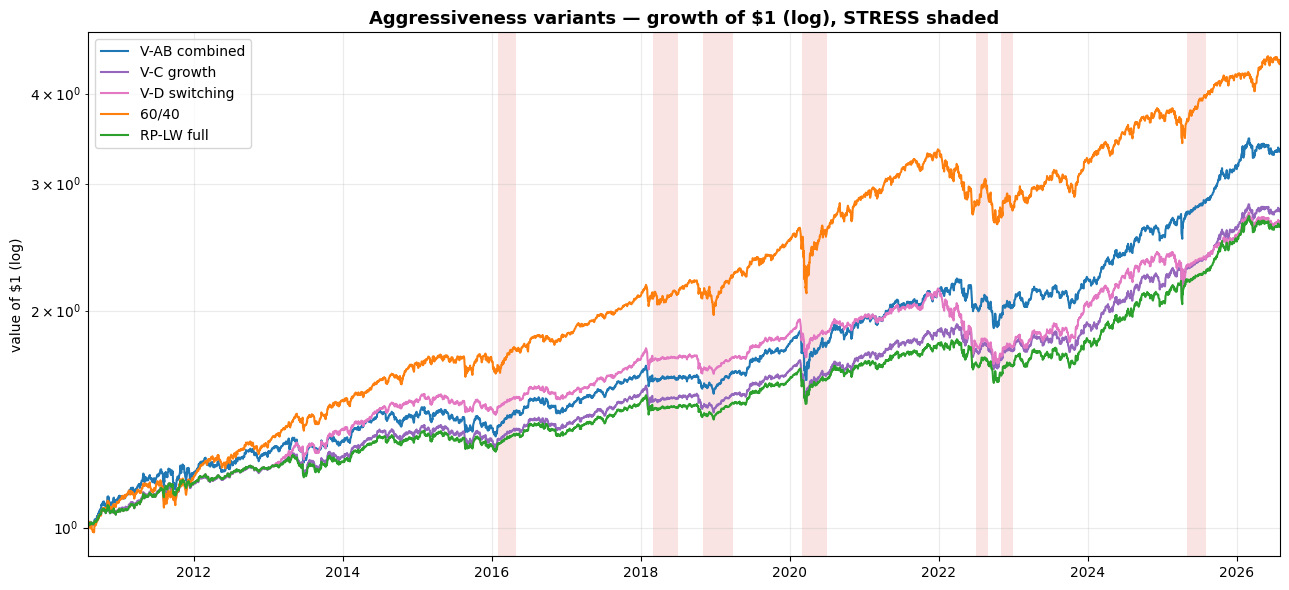

In [8]:
stress_months = [T for T in reg.index if reg.loc[T, "official_v2"] == "STRESS"]
def shade_stress(ax, x0, x1):
    ri = reg.index
    for T in stress_months:
        p = ri.get_loc(T); end = ri[p + 1] if p + 1 < len(ri) else x1
        a, b = max(T, x0), min(end, x1)
        if a < b:
            ax.axvspan(a, b, color="#d62728", alpha=0.13, zorder=0, linewidth=0)

sel = ["V-AB combined", "V-C growth", "V-D switching", "60/40", "RP-LW full"]
col = {"V-AB combined": "#1f77b4", "V-C growth": "#9467bd", "V-D switching": "#e377c2",
       "60/40": "#ff7f0e", "RP-LW full": "#2ca02c"}
x0, x1 = daily_df.index.min(), daily_df.index.max()
fig, ax = plt.subplots(figsize=(13, 6))
shade_stress(ax, x0, x1)
for n in sel:
    e = (1 + daily_df[n]).cumprod(); ax.plot(e.index, e.values, label=n, color=col[n], linewidth=1.5, zorder=2)
ax.set_yscale("log"); ax.set_xlim(x0, x1)
ax.set_title("Aggressiveness variants — growth of $1 (log), STRESS shaded", fontweight="bold", fontsize=13)
ax.set_ylabel("value of $1 (log)"); ax.set_xlabel(""); ax.legend(loc="upper left"); ax.grid(True, which="both", alpha=0.25)
plt.tight_layout(); plt.show()

### Eval 5 — Bootstrap: are the variant Sharpe differences real?

Moving-block (6 months, 10,000 resamples), paired on monthly returns. If the 95% CI
spans 0, it is a **TIE**.

In [9]:
M = pd.DataFrame({n: mdaily[n] for n in panels}).dropna()
shy_mm = shy_m.reindex(M.index)
np.random.seed(42)
B, L = 10000, 6; n = len(M); nb = int(np.ceil(n / L))
starts = np.random.randint(0, n - L + 1, size=(B, nb))
IDX = (starts[:, :, None] + np.arange(L)[None, None, :]).reshape(B, nb * L)[:, :n]
def sh_rows(mat): return np.sqrt(12) * mat.mean(1) / mat.std(1)
def boot(a, b):
    exA = (M[a] - shy_mm).values; exB = (M[b] - shy_mm).values
    d = sh_rows(exA[IDX]) - sh_rows(exB[IDX])
    obs = shp(M[a] - shy_mm) - shp(M[b] - shy_mm)
    lo, hi = np.percentile(d, [2.5, 97.5]); flip = float(np.mean(np.sign(d) != np.sign(obs)))
    return obs, lo, hi, flip
# ("V-AB combined", "SPY") added at the final-submission review: the README claims a Sharpe tie with BOTH
# benchmarks, but only the 60/40 pair had been tested directly. Appended last: shared IDX, earlier pairs unchanged.
for a, b in [("V-AB combined", "RP-LW base"), ("V-AB combined", "60/40"), ("V-D switching", "60/40"),
             ("V-AB combined", "SPY")]:
    obs, lo, hi, flip = boot(a, b)
    verdict = "significant" if (lo > 0 or hi < 0) else "TIE (CI spans 0)"
    print(f"{a} - {b}: diff={obs:+.3f}  CI=[{lo:+.3f},{hi:+.3f}]  sign_flip={flip:.3f}  -> {verdict}")

V-AB combined - RP-LW base: diff=-0.019  CI=[-0.190,+0.113]  sign_flip=0.390  -> TIE (CI spans 0)
V-AB combined - 60/40: diff=-0.120  CI=[-0.467,+0.211]  sign_flip=0.221  -> TIE (CI spans 0)
V-D switching - 60/40: diff=-0.191  CI=[-0.436,+0.058]  sign_flip=0.066  -> TIE (CI spans 0)
V-AB combined - SPY: diff=-0.087  CI=[-0.461,+0.253]  sign_flip=0.295  -> TIE (CI spans 0)


## Honest closing

- **These five variants were chosen after seeing Steps 8–9.** That is in-sample
  tuning, stated plainly. The metrics/target tables show whether any variant closed
  the CALM-months gap while keeping the crisis profile — read them directly rather
  than trusting a single headline number.
- **The Sharpe differences (Eval 5) are almost certainly ties**, as in Step 9 — 16
  years is too little to resolve ~0.1 Sharpe. Do not over-read a variant "winning"
  the ranking by a few basis points of Sharpe.
- **True validation is out-of-sample paper-tracking**, not this backtest. Nothing
  here has been validated forward.
- **V-D's specific fragility:** it bets the *entire* book on the detector at every
  transition — a wrong CALM→defensive call (or the reverse) at a turn moves ~100% of
  the portfolio. It made 16 switches over the sample (see Eval 3), two of them
  60% turnover events; a single mistimed switch in live trading would dominate its
  P&L. Its backtest turnover/cost are far above the other variants — reported, not
  hidden. This concentration risk is the reason a full-switch design is attractive on
  paper and dangerous in practice.

No parameters were touched beyond the five declared variants. One run.

## Conclusions at a glance

Four summary visuals. **No strategy is recomputed here** — they reuse the daily
returns already computed above (`daily_df`, the Step-10 tracks) plus **EW-1/6** read
from `outputs/backtest_returns.parquet` (Step 8). Same evaluation window throughout.
Tracks shown: V-AB combined, RP-LW base, RP-LW full, 60/40, SPY (EW-1/6 appears only
in the risk-return scatter).

In [10]:
bt8 = pd.read_parquet(OUT_DIR / "backtest_returns.parquet")
GL = pd.DataFrame({
    "V-AB combined": daily_df["V-AB combined"],
    "RP-LW base":    daily_df["RP-LW base"],
    "RP-LW full":    daily_df["RP-LW full"],
    "60/40":         daily_df["60/40"],
    "SPY":           daily_df["SPY"],
    "EW-1/6":        bt8["EW-1/6"],
}).dropna()
GCOL = {"V-AB combined": "#1f77b4", "RP-LW base": "#17becf", "RP-LW full": "#2ca02c",
        "60/40": "#ff7f0e", "SPY": "#333333", "EW-1/6": "#9467bd"}
print(f"summary frame: {GL.shape}  {GL.index.min().date()} -> {GL.index.max().date()}")

summary frame: (4025, 6)  2010-08-02 -> 2026-07-31


### G1 — Worst intra-year drawdown, by calendar year

Deepest peak-to-trough drawdown *within* each calendar year (peaks reset at each
year start), computed from daily curves. Grouped bars point downward — V-AB vs
60/40 vs SPY.

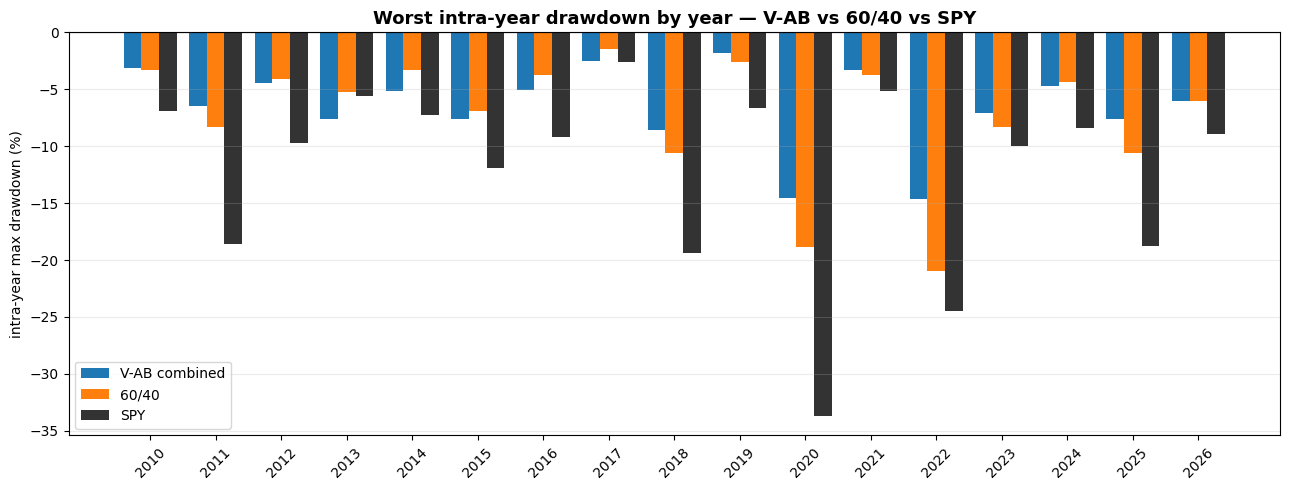

In [11]:
YR = sorted(set(GL.index.year))
def intra_year_mdd(r):
    out = {}
    for y in YR:
        ry = r[r.index.year == y]
        if len(ry):
            eq = (1 + ry).cumprod()
            out[y] = (eq / eq.cummax() - 1).min() * 100
    return pd.Series(out)

g1 = pd.DataFrame({t: intra_year_mdd(GL[t]) for t in ["V-AB combined", "60/40", "SPY"]})
xs = np.arange(len(g1)); w = 0.27
fig, ax = plt.subplots(figsize=(13, 5))
for i, t in enumerate(["V-AB combined", "60/40", "SPY"]):
    ax.bar(xs + (i - 1) * w, g1[t], w, label=t, color=GCOL[t])
ax.set_xticks(xs); ax.set_xticklabels(g1.index, rotation=45)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Worst intra-year drawdown by year — V-AB vs 60/40 vs SPY", fontweight="bold", fontsize=13)
ax.set_ylabel("intra-year max drawdown (%)"); ax.legend(); ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### G2 — Risk-return scatter (the one-figure verdict)

X = |max drawdown|, Y = CAGR, one point per track. Faint dashed lines are
iso-Calmar (CAGR = Calmar × |maxDD|). **Up-and-left is better** (more return per
unit of drawdown).

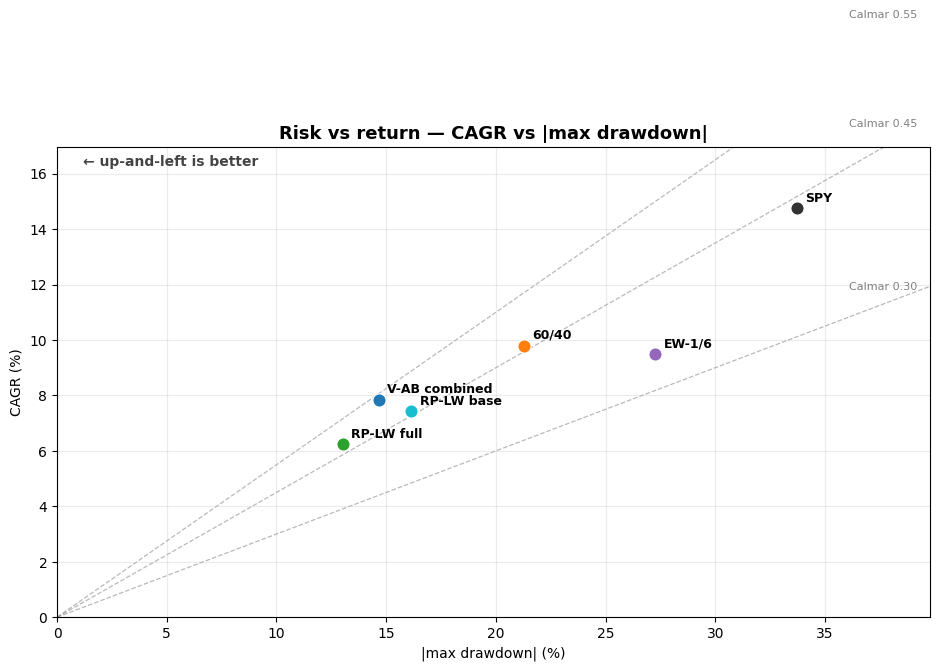

In [12]:
def cagr_of(r):
    eq = (1 + r).cumprod(); return (eq.iloc[-1] ** (252 / len(r)) - 1) * 100
def absmdd(r):
    eq = (1 + r).cumprod(); return abs((eq / eq.cummax() - 1).min()) * 100

pts = {t: (absmdd(GL[t]), cagr_of(GL[t])) for t in GL.columns}
xmax = max(x for x, _ in pts.values()) * 1.18
fig, ax = plt.subplots(figsize=(9.5, 7))
xline = np.linspace(0, xmax, 50)
for cal in [0.30, 0.45, 0.55]:
    ax.plot(xline, cal * xline, ls="--", color="grey", alpha=0.55, linewidth=0.9, zorder=1)
    ax.text(xmax * 0.985, cal * xmax * 0.985, f"Calmar {cal:.2f}", color="grey",
            fontsize=8, ha="right", va="bottom")
for t, (x, y) in pts.items():
    ax.scatter(x, y, color=GCOL[t], s=90, zorder=3, edgecolor="white", linewidth=0.8)
    ax.annotate(t, (x, y), xytext=(6, 5), textcoords="offset points", fontsize=9, fontweight="bold")
ax.annotate("← up-and-left is better", xy=(0.03, 0.96), xycoords="axes fraction",
            fontsize=10, color="#444", fontweight="bold")
ax.set_xlim(0, xmax); ax.set_ylim(0, max(y for _, y in pts.values()) * 1.15)
ax.set_title("Risk vs return — CAGR vs |max drawdown|", fontweight="bold", fontsize=13)
ax.set_xlabel("|max drawdown| (%)"); ax.set_ylabel("CAGR (%)"); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.show()

### G3 — Pain index (mean drawdown)

Average depth below the running peak over the whole period (daily). It captures
**time-under-water × depth** — what a single max-drawdown number misses.

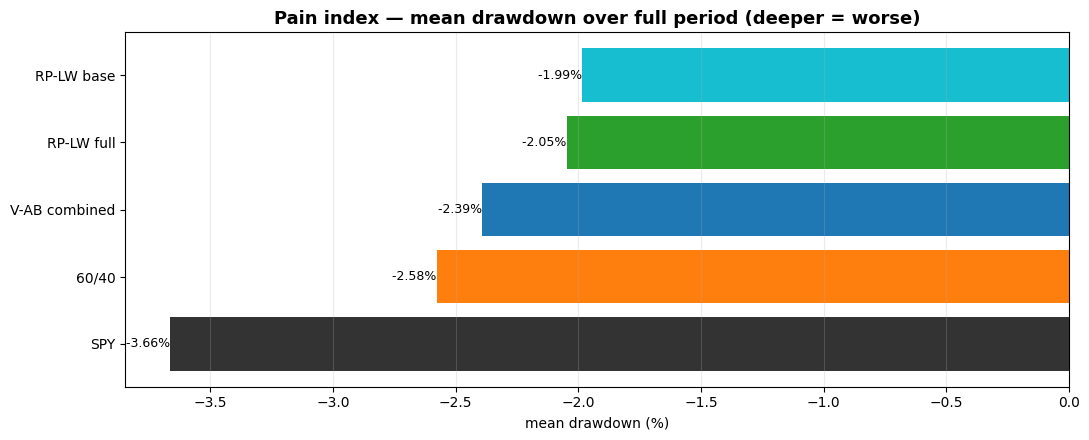

In [13]:
def pain(r):
    eq = (1 + r).cumprod(); return (eq / eq.cummax() - 1).mean() * 100

g3 = pd.Series({t: pain(GL[t]) for t in ["V-AB combined", "RP-LW base", "RP-LW full", "60/40", "SPY"]}).sort_values()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(g3.index, g3.values, color=[GCOL[t] for t in g3.index])
for t, v in g3.items():
    ax.text(v, t, f" {v:.2f}%", va="center", ha="right" if v < 0 else "left", fontsize=9)
ax.set_title("Pain index — mean drawdown over full period (deeper = worse)", fontweight="bold", fontsize=13)
ax.set_xlabel("mean drawdown (%)"); ax.grid(True, axis="x", alpha=0.25)
plt.tight_layout(); plt.show()

### G4 — Monthly return distribution: V-AB vs SPY

Overlaid histograms (1%-wide bins), vertical line at 0. The system's distribution
should read visibly narrower with a shorter left tail.

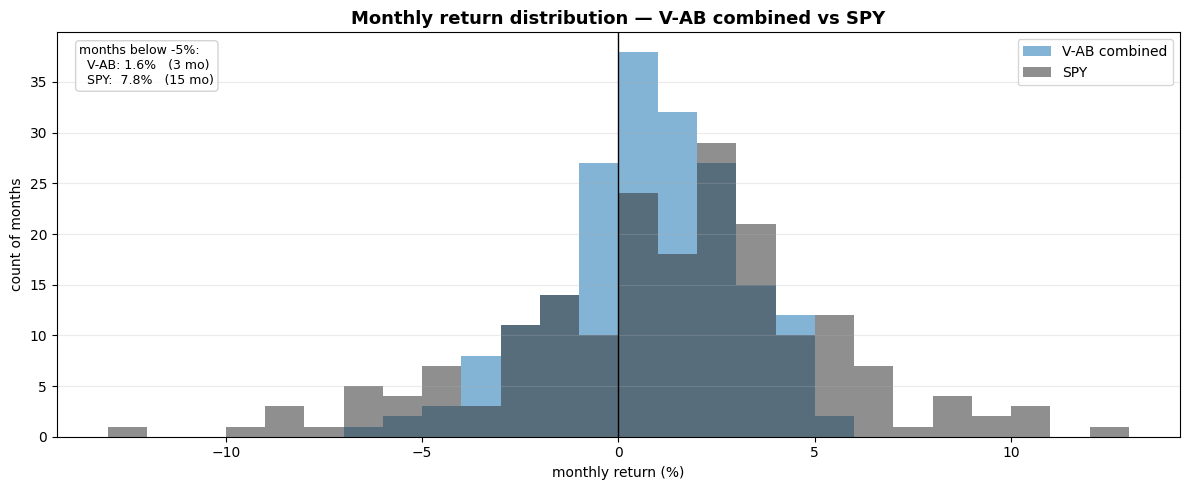

In [14]:
mAB = ((1 + GL["V-AB combined"]).resample("ME").prod() - 1) * 100
mSPY = ((1 + GL["SPY"]).resample("ME").prod() - 1) * 100
lo, hi = np.floor(min(mAB.min(), mSPY.min())), np.ceil(max(mAB.max(), mSPY.max()))
bins = np.arange(lo, hi + 1, 1.0)
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(mAB, bins=bins, alpha=0.55, label="V-AB combined", color=GCOL["V-AB combined"])
ax.hist(mSPY, bins=bins, alpha=0.55, label="SPY", color=GCOL["SPY"])
ax.axvline(0, color="black", linewidth=1.0)
ax.set_title("Monthly return distribution — V-AB combined vs SPY", fontweight="bold", fontsize=13)
ax.set_xlabel("monthly return (%)"); ax.set_ylabel("count of months"); ax.legend()
ax.grid(True, axis="y", alpha=0.25)
txt = (f"months below -5%:\n  V-AB: {(mAB < -5).mean()*100:.1f}%   ({(mAB < -5).sum()} mo)\n"
       f"  SPY:  {(mSPY < -5).mean()*100:.1f}%   ({(mSPY < -5).sum()} mo)")
ax.text(0.02, 0.97, txt, transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="#ccc"))
plt.tight_layout(); plt.show()